In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pints
import pints.io
import pints.plot
import scipy.interpolate
from collections import defaultdict
import matplotlib
import mechanistic_model

Read in data, and create a new variable (`weight2`) for weight squared.

In [ ]:
df = pd.read_csv('data/df_covariates_better_date.csv')

df['weight2'] = df['weight'] ** 2

Get the outcome variables and numbers of initial preys.

In [16]:
ns_prey_eaten = df['n_prey_eaten']
ns_prey_initial = df['n_prey_initial']

all_possible_initial_ns_prey = sorted(list(set(ns_prey_initial)))

Define two models with different configurations of the covariates.

The basic model structure is:

$$\log{a} = c_a + \beta_a x_a$$
$$\log{r} = c_r + \beta_r x_r$$

Model 1: weight covariates associated with r; all other covariates associated with a.

Model 2: a is constant; all covaraites are associated with r.

In [4]:
class FunctionalResponseRegressionModel:

    def __init__(self, X_a, X_r):
        self.X_a = X_a
        self.X_r = X_r

        self.num_a_params = X_a.shape[1]
        self.num_r_params = X_r.shape[1]

In [26]:
X_a = df[["f.acc_condH",
          "f.acc_condM",
          "f.acc_condT", 
          "f.exp_condH",
          "f.exp_condM",
          "f.exp_condT",
          "f.week6",
          "f.acc_condH:f.week6",
          "f.acc_condM:f.week6",
          "f.acc_condT:f.week6"
]]
X_a.insert(0, 'Ones', 1) 

X_r = df[["weight", "weight2",]]
X_r.insert(0, 'Ones', 1)

model_1 = FunctionalResponseRegressionModel(X_a, X_r)

In [29]:
X_a = df[[]]
X_a.insert(0, 'Ones', 1) 

X_r = df[["f.acc_condH",
          "f.acc_condM", 
          "f.acc_condT",  
          "f.exp_condH",
          "f.exp_condM",
          "f.exp_condT",
          "f.week6",
          "f.acc_condH:f.week6",
          "f.acc_condM:f.week6", 
          "f.acc_condT:f.week6", 
          "weight",
          "weight2"]]

X_r.insert(0, 'Ones', 1)

model_2 = FunctionalResponseRegressionModel(X_a, X_r)

Prior Predictive Checks. These are run by drawing samples from the prior, multiplying by the covariates to obtain $a$ and $r$ values, running these values through the model to obtain numbers of prey eaten, then comparing to the data.

In [60]:
total_num_params = model_1.num_a_params + model_1.num_r_params

prior_var = 10.0
prior_var_weight = 1.0

prior_model_1 = pints.MultivariateGaussianLogPrior(
    [0] * total_num_params,
    np.diag([prior_var] * (total_num_params - 2) + [prior_var_weight] * 2)
)

In [61]:
def prior_predictive(prior, num_prior_samples, model):

    prior_a_values = []
    prior_r_values = []
    prior_dists_over_num_eaten = defaultdict(list)
    data_dists_over_num_eaten = defaultdict(list)

    prior_samples = prior.sample(num_prior_samples)

    X_a = model.X_a
    X_r = model.X_r

    for x in prior_samples:

        for n_prey_eaten, n_prey_initial, x_a, x_r in zip(
            ns_prey_eaten, ns_prey_initial, X_a.to_numpy(), X_r.to_numpy()
        ):
        
            beta_a = x[:model.num_a_params]
            beta_r = x[model.num_a_params:]

            a = mechanistic_model.a_parameter_creator(beta_a, x_a)
            r = mechanistic_model.a_parameter_creator(beta_r, x_r)

            prior_a_values.append(a)
            prior_r_values.append(r)
        
            p_eaten = mechanistic_model.solve_system_simple_h_simplex(n_prey_initial, a, r)

            prior_dists_over_num_eaten[n_prey_initial].append(np.asarray(p_eaten))

            # For the data, create a vector of 0 in all possibilities, except for a 
            # 1 for the actual number of preys eaten.
            data = [0] * (n_prey_initial + 1)
            data[n_prey_eaten] = 1
            data_dists_over_num_eaten[n_prey_initial].append(np.asarray(data))

    return prior_a_values, prior_r_values, prior_dists_over_num_eaten, data_dists_over_num_eaten

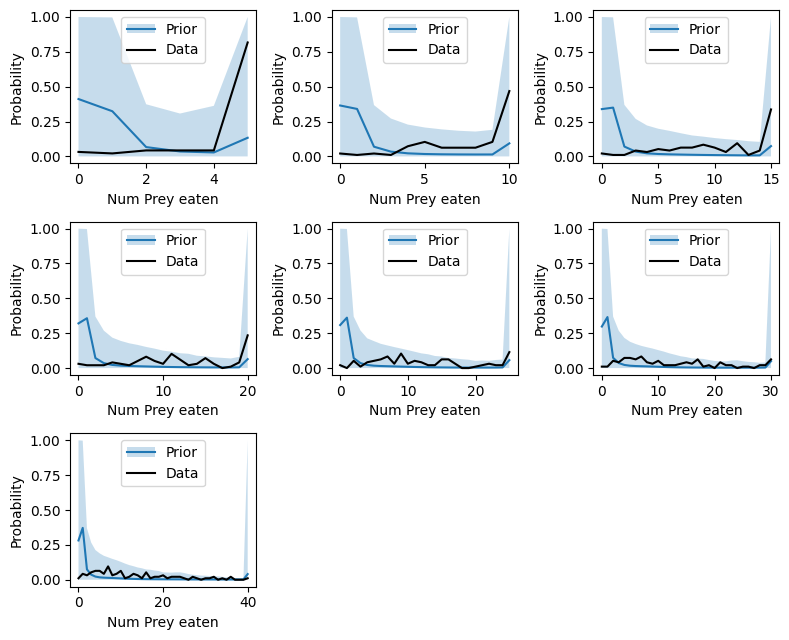

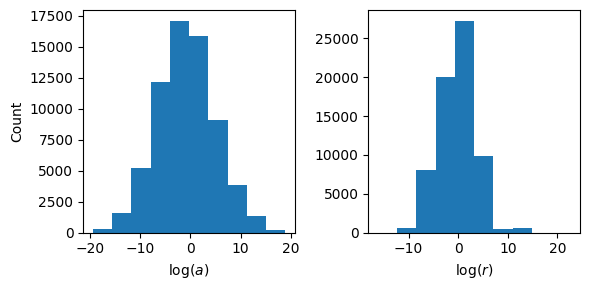

In [62]:
# Run for Model 1

prior_a_values, prior_r_values, prior_dists_over_num_eaten, data_dists_over_num_eaten = prior_predictive(
    prior_model_1,
    100,
    model_1,
)

fig = plt.figure(figsize=(8, 6.5))

for i, n in enumerate(all_possible_initial_ns_prey):
    ax = fig.add_subplot(3, 3, i+1)
    
    m = prior_dists_over_num_eaten[n]
    d = data_dists_over_num_eaten[n]

    x = np.arange(n+1)
    l1, = ax.plot(x, np.mean(m, axis=0), label='Inferred')
    p1 = ax.fill_between(x, np.percentile(m, 2.5, axis=0), np.percentile(m, 97.5, axis=0), alpha=0.25)

    l2, = ax.plot(x, np.mean(d, axis=0), color='k', label='Data')

    ax.legend(((l1, p1), l2), ['Prior', 'Data'])

    ax.set_xlabel('Num Prey eaten')
    ax.set_ylabel('Probability')

fig.set_tight_layout(True)
plt.show()

fig = plt.figure(figsize=(6, 3))
ax = fig.add_subplot(1, 2, 1)
ax.hist(np.log(prior_a_values))
ax.set_xlabel(r'$\log(a)$')
ax.set_ylabel('Count')

ax = fig.add_subplot(1, 2, 2)
ax.hist(np.log(prior_r_values))
ax.set_xlabel(r'$\log(r)$')

fig.set_tight_layout(True)
plt.show()


In [63]:
total_num_params = model_2.num_a_params + model_2.num_r_params

prior_var_a = 20.0
prior_var = 10.0
prior_var_weight = 1.0

prior_model_2 = pints.MultivariateGaussianLogPrior(
    [0] * total_num_params,
    np.diag([prior_var_a] + [prior_var] * (total_num_params - 3) + [prior_var_weight] * 2)
)

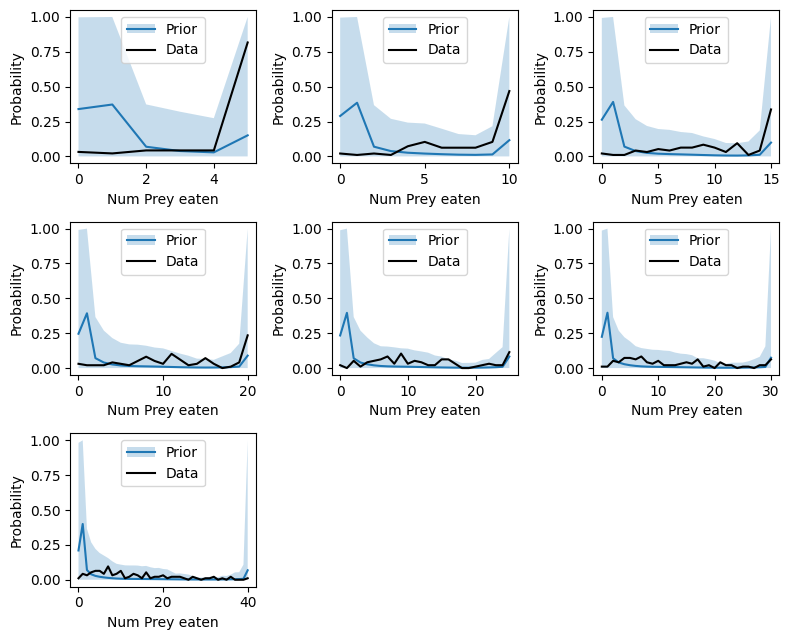

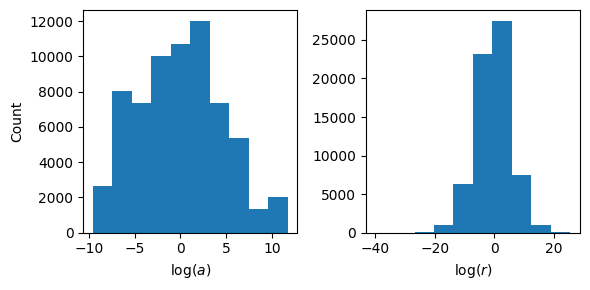

In [64]:
# Run for Model 2

prior_a_values, prior_r_values, prior_dists_over_num_eaten, data_dists_over_num_eaten = prior_predictive(
    prior_model_2,
    100,
    model_2,
)

fig = plt.figure(figsize=(8, 6.5))

for i, n in enumerate(all_possible_initial_ns_prey):
    ax = fig.add_subplot(3, 3, i+1)
    
    m = prior_dists_over_num_eaten[n]
    d = data_dists_over_num_eaten[n]

    x = np.arange(n+1)
    l1, = ax.plot(x, np.mean(m, axis=0), label='Inferred')
    p1 = ax.fill_between(x, np.percentile(m, 2.5, axis=0), np.percentile(m, 97.5, axis=0), alpha=0.25)

    l2, = ax.plot(x, np.mean(d, axis=0), color='k', label='Data')

    ax.legend(((l1, p1), l2), ['Prior', 'Data'])

    ax.set_xlabel('Num Prey eaten')
    ax.set_ylabel('Probability')

fig.set_tight_layout(True)
plt.show()

fig = plt.figure(figsize=(6, 3))
ax = fig.add_subplot(1, 2, 1)
ax.hist(np.log(prior_a_values))
ax.set_xlabel(r'$\log(a)$')
ax.set_ylabel('Count')

ax = fig.add_subplot(1, 2, 2)
ax.hist(np.log(prior_r_values))
ax.set_xlabel(r'$\log(r)$')

fig.set_tight_layout(True)
plt.show()


Run Inference

In [69]:
class Likelihood(pints.LogPDF):
    def __init__(self, ns_prey_eaten, ns_prey_initial, model):
        super().__init__()
        self.ns_prey_eaten = ns_prey_eaten
        self.ns_prey_initial = ns_prey_initial

        self.X_a = model.X_a
        self.X_r = model.X_r

        self.num_a_params = model.num_a_params
        self.num_r_params = model.num_r_params

    def __call__(self, x):
        beta_a = x[:self.num_a_params]
        beta_r = x[self.num_a_params:]

        ll, _ = mechanistic_model.log_likelihood_all_fish(ns_prey_eaten, ns_prey_initial, beta_a, beta_r, self.X_a, self.X_r)
        return ll
    
    def n_parameters(self):
        return self.num_a_params + self.num_r_params

In [ ]:
ll_1 = Likelihood(ns_prey_eaten, ns_prey_initial, model_1)

posterior = pints.LogPosterior(ll_1, prior_model_1)

best_opt_result = -np.inf
best_opt_x = -1
for i in range(10):
    opt = pints.OptimisationController(
        posterior,
        prior_model_1.sample(),
        method=pints.CMAES,
    )
    opt.set_max_iterations(400)
    x, err = opt.run()
    if err > best_opt_result:
        best_opt_x = np.copy(x)
        best_opt_result = err
    
x = best_opt_x

mcmc = pints.MCMCController(
    posterior,
    3,
    [best_opt_x,best_opt_x, best_opt_x],
    method=pints.HaarioBardenetACMC,
)

mcmc.set_max_iterations(50000)

mcmc.set_chain_filename('outputs/model_1_mcmc.csv')

chains_opt = mcmc.run()

Maximising LogPDF
Using Covariance Matrix Adaptation Evolution Strategy (CMA-ES)
Running in sequential mode.
Population size: 11
Iter. Eval.  Best      Current   Time m:s
0     11     -13614.97 -13614.97   0:00.7
1     22     -13611.38 -13611.38   0:01.4
2     33     -13583.75 -13583.75   0:02.1

----------------------------------------
Unexpected termination.
Current score: -13583.745228423928
Current position:
-1.38090871835367568e+00
-4.07750558189728096e+00
-4.57112252791114493e+00
 3.47022532991780075e+00
 3.47958112831234845e-01
 4.46677130884854190e+00
-1.93627039706655935e+00
-1.25467547257979206e-01
-5.01512546476326104e+00
 2.62932357777242753e+00
-4.48291877876083955e+00
-1.24444825637689327e+00
-9.18922655096125890e-02
-1.19941141545160268e+00
----------------------------------------


KeyboardInterrupt: 

In [ ]:
ll_2 = Likelihood(ns_prey_eaten, ns_prey_initial, model_2)

posterior = pints.LogPosterior(ll_2, prior_model_2)

best_opt_result = -np.inf
best_opt_x = -1
for i in range(10):
    opt = pints.OptimisationController(
        posterior,
        prior_model_1.sample(),
        method=pints.CMAES,
    )
    opt.set_max_iterations(400)
    x, err = opt.run()
    if err > best_opt_result:
        best_opt_x = np.copy(x)
        best_opt_result = err

x = best_opt_x

mcmc = pints.MCMCController(
    posterior,
    3,
    [best_opt_x,best_opt_x, best_opt_x],
    method=pints.HaarioBardenetACMC,
)

mcmc.set_max_iterations(50000)

mcmc.set_chain_filename('outputs/model_2_mcmc.csv')

chains_opt = mcmc.run()

Maximising LogPDF
Using Covariance Matrix Adaptation Evolution Strategy (CMA-ES)
Running in sequential mode.
Population size: 11
Iter. Eval.  Best      Current   Time m:s
0     11     -6188.226 -6188.226   0:00.9
1     22     -6148.785 -6148.785   0:01.7

----------------------------------------
Unexpected termination.
Current score: -6148.785399169137
Current position:
 1.78041591182659720e-01
 5.25643077346598631e+00
-6.81033088713247636e-02
-2.99504688969999755e+00
-1.52625010666218808e+00
-1.01328088467823152e+00
 1.32266110763635703e+00
-2.32963651177994535e+00
 3.49463268169376340e+00
-6.21048103762296688e-01
-3.88209547386302667e+00
 3.63522398176156170e+00
 9.01424749845461809e-02
-1.41850956446315601e+00
----------------------------------------


KeyboardInterrupt: 